# Лабораторная работа 3. Кластеризация

## 1. Введение. Краткое описание целей и задач работы

#### **Цель работы:** изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

#### **Задачи:**

1. Загрузить датасет для задачи кластеризации / классификации (например, с платформы Kaggle). Провести дескриптивный анализ данных: определить размерность, типы признаков, наличие пропусков. Оценить распределение переменных (близость к нормальному) с использованием визуализации (гистограммы). Оценить информационную значимость признаков. Проверить условие применения кластеризации: отсутствие классов, осмысленность кластеризации, отсутствие выбросов.

2. Выполнить стандартизацию / нормализацию числовых признаков. Обосновать выбор метода масштабирования. Построить матрицу диаграмм рассеивания для визуальной оценки структуры данных, предположительного количества кластеров и типа кластерной структуры. Аргументировать выбор методов кластеризации на основе формы, размера и плотности кластеров.

3. Реализовать кластеризацию двумя различными методами на выбор: K-means (K-средних); иерархическая кластеризация; DBSCAN; EM-алгоритм (Gaussian Mixture). Для методов, требующих задания числа кластеров (K-means, иерархическая), подобрать оптимальное значение k с использованием: метода локтя и / или анализа силуэта.

4. Рассчитать метрики качества для обоих методов: внутренние и внешние. Оценить расстояние между кластерами, внутрикластерные расстояния, компактность кластеров, центры кластеров. Опционально, если известно разделение на классы, посчитать: индекс Rand, индекс Жаккара и др. внешние метрики. Привести содержательную интерпретацию полученных значений.

5. Исследовать влияние параметров одного из методов (например, ε и min_samples для DBSCAN или количества кластеров k для K-means) на качество кластеризации.

6. Визуализировать полученные кластеры в пространстве признаков (использовать PCA для снижения размерности при необходимости). Проанализировать центры кластеров и дать содержательную интерпретацию выделенных групп. Сравнить результаты, полученные двумя разными методами.

## 2. Описание датасета

### Импорт библиотек и настройки

Импортируем pandas/numpy для работы с данными, matplotlib/seaborn для визуализации, модули scikit-learn для масштабирования, кластеризации и метрик, scipy для дендрограммы и тестов на нормальность.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score,
                             adjusted_mutual_info_score)
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.stats import shapiro

import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

print('pandas:', pd.__version__)
print('numpy :', np.__version__)

pandas: 2.2.3
numpy : 2.4.6


**Датасет**: Glass Identification Database (UCI Machine Learning Repository).

**Задача**: кластеризация — выделить группы образцов стекла на основе их химического состава, не используя информацию о типе стекла. Тип стекла (Type) сохраняется отдельно и используется только для внешней оценки качества кластеризации.

**Объектов**: 214

**Признаков**: 9 числовых + 1 целевой (тип стекла)

**Классов** (для внешней оценки): 6 (тип 4 в базе отсутствует)

In [ ]:
df = pd.read_csv('glass.csv')
df.columns = df.columns.str.strip()

# В исходном CSV из UCI есть служебный столбец Id — удаляем, если присутствует
if 'Id' in df.columns:
    df = df.drop(columns=['Id'])

print('Размер датасета:', df.shape)
print('\nПервые 5 строк:')
print(df.head())
print('\nТипы данных и non-null counts:')
df.info()

Размер датасета: (214, 10)

Первые 5 строк:
        RI     Na    Mg    Al     Si     K    Ca   Ba   Fe  Type
0  1.52101  13.64  4.49  1.10  71.78  0.06  8.75  0.0  0.0     1
1  1.51761  13.89  3.60  1.36  72.73  0.48  7.83  0.0  0.0     1
2  1.51618  13.53  3.55  1.54  72.99  0.39  7.78  0.0  0.0     1
3  1.51766  13.21  3.69  1.29  72.61  0.57  8.22  0.0  0.0     1
4  1.51742  13.27  3.62  1.24  73.08  0.55  8.07  0.0  0.0     1

Типы данных и non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-n

### Описание признаков

| Признак | Тип | Описание |
|---|---|---|
| `RI` | числовой | показатель преломления (refractive index) |
| `Na` | числовой | содержание натрия (вес. % оксида) |
| `Mg` | числовой | содержание магния, вес. % |
| `Al` | числовой | содержание алюминия, вес. % |
| `Si` | числовой | содержание кремния, вес. % |
| `K` | числовой | содержание калия, вес. % |
| `Ca` | числовой | содержание кальция, вес. % |
| `Ba` | числовой | содержание бария, вес. % |
| `Fe` | числовой | содержание железа, вес. % |
| **`Type`** | **целевой** | **тип стекла: 1 — building_windows_float_processed, 2 — building_windows_non_float_processed, 3 — vehicle_windows_float_processed, 5 — containers, 6 — tableware, 7 — headlamps** |

Все 9 признаков — непрерывные числовые. Пропусков нет. Столбец `Type` в кластеризации **не участвует** и отделяется в `y_true` для расчёта внешних метрик (ARI, AMI).

In [ ]:
y_true = df['Type'].copy()           # только для внешней оценки
X_raw  = df.drop(columns=['Type'])   # матрица признаков для кластеризации

print('Признаки:', X_raw.columns.tolist())
print('Распределение типов стекла (для справки):')
print(y_true.value_counts().sort_index())

Признаки: ['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']
Распределение типов стекла (для справки):
Type
1    70
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64


### Характеристика целевой переменной:

Хотя целевая переменная `Type` не используется при обучении кластеризации, её анализ важен для последующей интерпретации внешних метрик. Классы сильно несбалансированы: типы 1 и 2 (оконное стекло) составляют 68% всех данных, в то время как тип 6 (столовая посуда) представлен всего 9 объектами.

Из-за такого дисбаланса мы не должны ожидать идеальных значений внешних метрик (например, ARI = 1.0). Если кластеризация выделит крупные группы оконных стёкол и контейнеров, но «потеряет» малочисленную столовую посуду, индекс ARI всё равно будет в районе 0.3–0.5, что для таких данных является **хорошим результатом**.

### Проверка пропусков и базовые статистики

In [ ]:
print('Пропуски по столбцам:')
print(X_raw.isnull().sum())

print('\nОписательные статистики:')
print(X_raw.describe().T)

Пропуски по столбцам:
RI    0
Na    0
Mg    0
Al    0
Si    0
K     0
Ca    0
Ba    0
Fe    0
dtype: int64

Описательные статистики:
    count       mean       std       min        25%       50%        75%       max
RI  214.0   1.518365  0.003037   1.51115   1.516522   1.51768   1.519157   1.53393
Na  214.0  13.407850  0.816604  10.73000  12.907500  13.30000  13.825000  17.38000
Mg  214.0   2.684533  1.442408   0.00000   2.115000   3.48000   3.600000   4.49000
Al  214.0   1.444907  0.499270   0.29000   1.190000   1.36000   1.630000   3.50000
Si  214.0  72.650935  0.774546  69.81000  72.280000  72.79000  73.087500  75.41000
K   214.0   0.497056  0.652192   0.00000   0.122500   0.55500   0.610000   6.21000
Ca  214.0   8.956963  1.423153   5.43000   8.240000   8.60000   9.172500  16.19000
Ba  214.0   0.175047  0.497219   0.00000   0.000000   0.00000   0.000000   3.15000
Fe  214.0   0.057009  0.097439   0.00000   0.000000   0.00000   0.100000   0.51000


### Анализ пропусков и базовых статистик:

Проверка показала, что в датасете **полностью отсутствуют пропуски** (Non-Null Count = 214 для всех признаков). Это существенно упрощает предобработку: нам не потребуется применять импутацию (заполнение пропущенных значений), и мы можем сразу переходить к анализу распределений и масштабированию.

Описательные статистики (`describe`) выявили критически важную особенность данных — **колоссальный разброс масштабов признаков**:
*   Среднее значение `Si` составляет ~72.65 (диапазон от 69.81 до 75.41), что на два порядка больше значений `Fe` (среднее ~0.057, диапазон от 0 до 0.51) и `Ba` (среднее ~0.175, диапазон от 0 до 3.15).
*   Стандартное отклонение `Si` (0.77) в десятки раз превышает стандартное отклонение `RI` (0.003) или `Fe` (0.097).

Если подать такие данные в алгоритм K-means или иерархическую кластеризацию «как есть», то признак `Si` будет полностью доминировать при расчёте евклидова расстояния. Кластеризация фактически будет проводиться только по одному этому признаку, а влияние остальных (например, магния или бария) сведётся к нулю.

Таким образом, результаты описательной статистики являются **прямым и неоспоримым обоснованием необходимости масштабирования признаков** на следующем шаге.

### Оценка распределения переменных

Построим гистограммы для каждого числового признака.



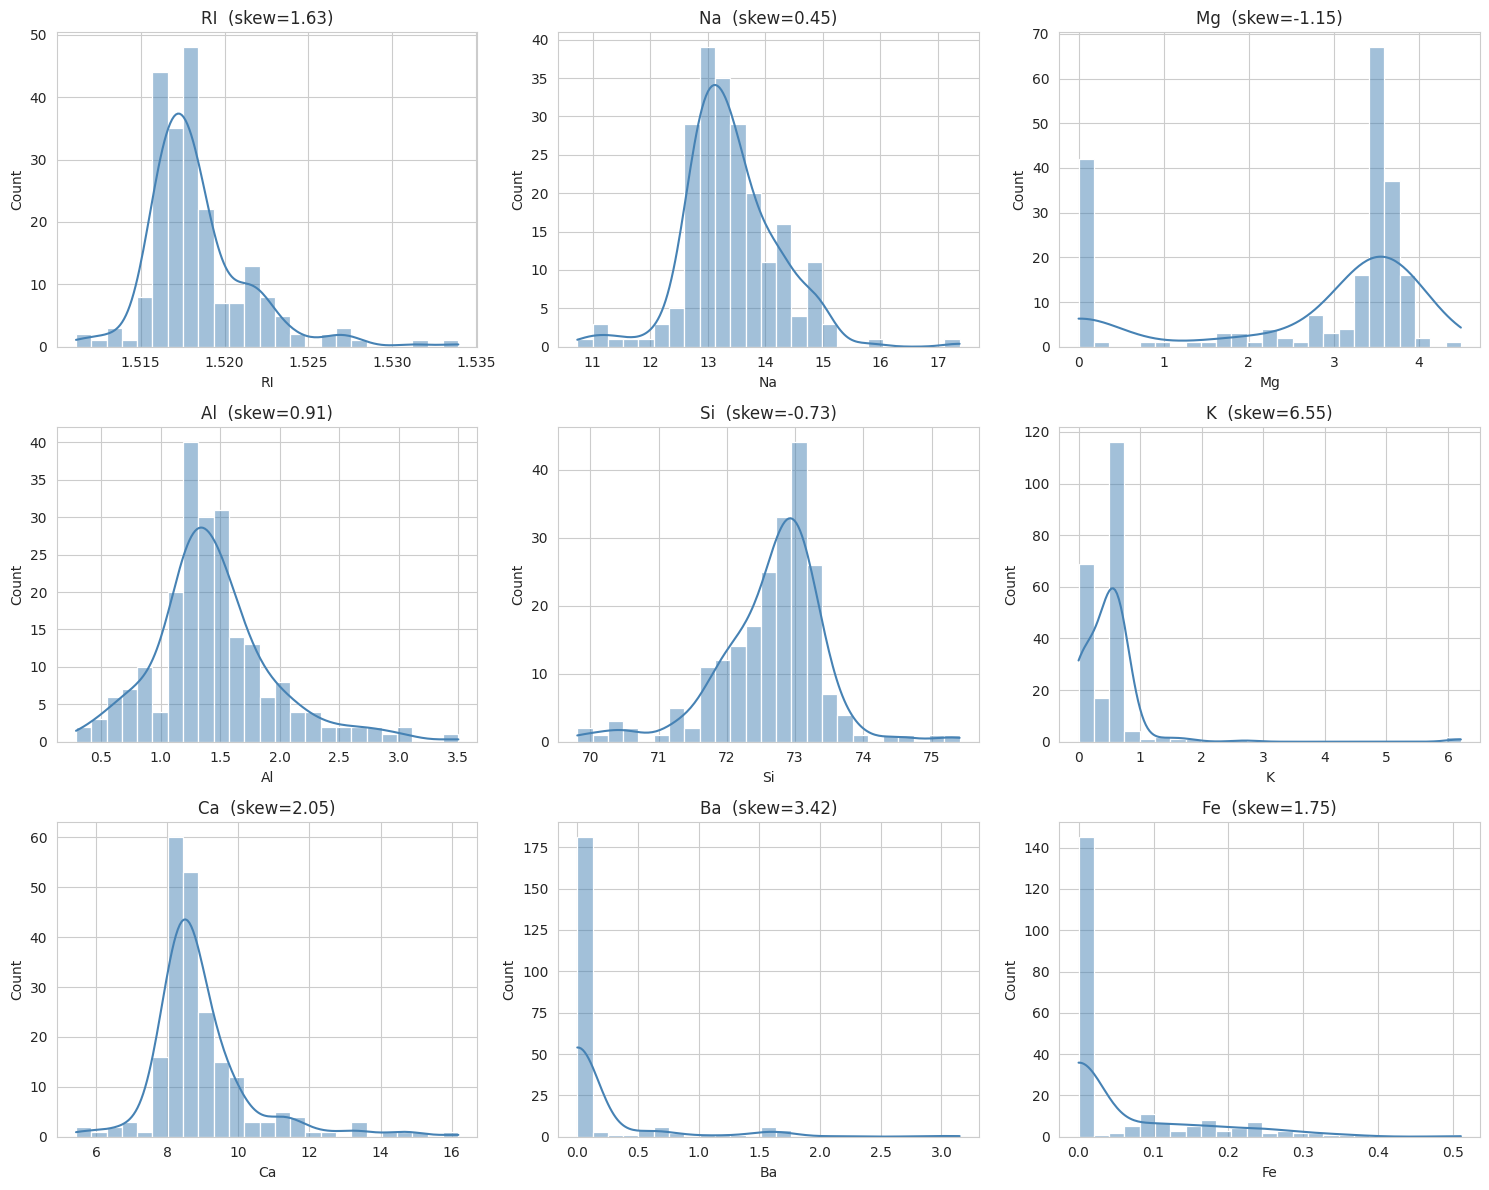

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(X_raw.columns):
    sns.histplot(X_raw[col], bins=25, kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f'{col}  (skew={X_raw[col].skew():.2f})')
plt.tight_layout()
plt.show()

### Анализ гистограмм:

Визуальный анализ распределений подтверждает расчёт коэффициентов асимметрии (skew):
*   Признаки `Na`, `Si`, `Mg` имеют умеренную асимметрию (skew от -1.15 до 0.45), их распределения близки к колоколообразным.
*   Признаки `RI`, `Al`, `Ca` имеют правостороннюю скошенность (skew от 0.9 до 2.05).
*   Признаки `K`, `Ba`, `Fe` обладают **экстремальной правосторонней скошенностью** (skew > 1.7). Большинство значений близки к нулю, но присутствуют редкие большие значения, которые вытягивают «хвост» распределения вправо.

Такая сильная неоднородность и наличие «тяжёлых хвостов» указывают на то, что обычная стандартизация (StandardScaler) может быть неэффективной, так как она чувствительна к экстремальным значениям.

### Проверка нормальности (тест Шапиро–Уилка)

In [ ]:
print(f'{"Признак":<6}{"W-статистика":>15}{"p-value":>12}{"Нормальность":>18}')
for col in X_raw.columns:
    stat, p = shapiro(X_raw[col])
    verdict = 'да' if p > 0.05 else 'нет'
    print(f'{col:<6}{stat:>15.4f}{p:>12.4f}{verdict:>18}')

Признак   W-статистика     p-value      Нормальность
RI             0.8676      0.0000               нет
Na             0.9458      0.0000               нет
Mg             0.6993      0.0000               нет
Al             0.9434      0.0000               нет
Si             0.9197      0.0000               нет
K              0.4416      0.0000               нет
Ca             0.7939      0.0000               нет
Ba             0.4086      0.0000               нет
Fe             0.6532      0.0000               нет


### Интерпретация теста на нормальность:

Для всех 9 признаков p-value < 0.05 (фактически равно 0.0000). Это означает, что мы **отвергаем гипотезу о нормальном распределении** для каждого из признаков.

В сочетании с результатами визуального анализа (гистограммы) это доказывает, что данные не подчиняются закону нормального распределения. Следовательно, методы, основанные на среднем значении и стандартном отклонении, будут работать некорректно. Это ключевой аргумент в пользу выбора робастного масштабирования на следующем этапе.

### Анализ выбросов

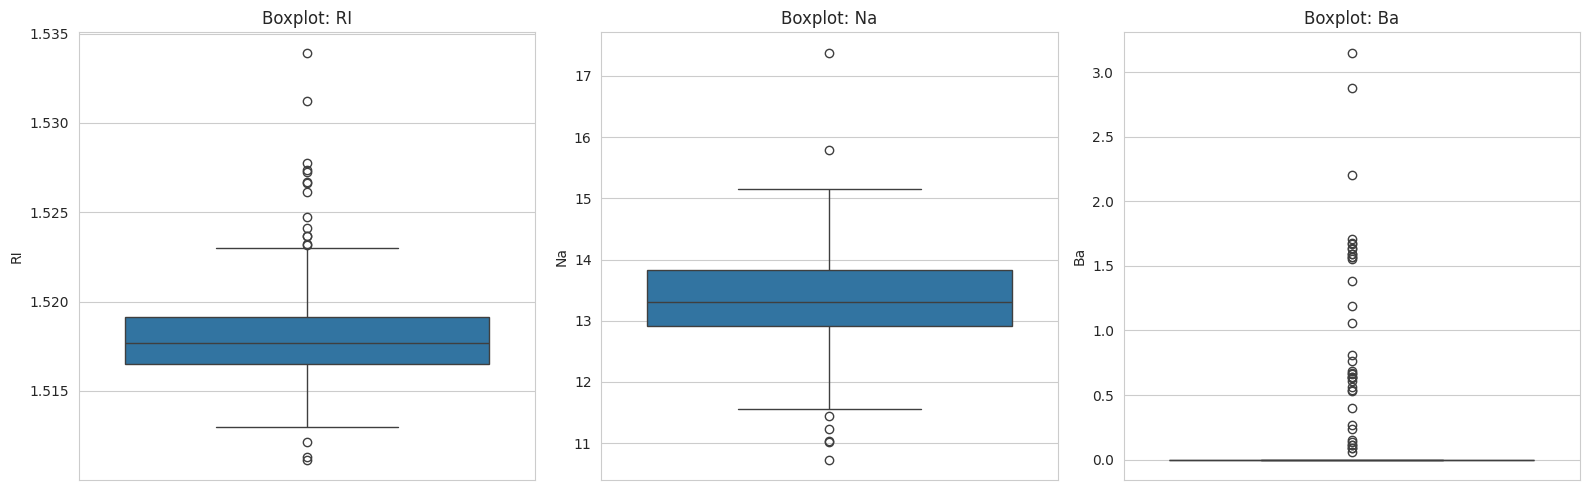


Признак      Q1      Q3     IQR  Выбросов   Доля, %
RI       1.517   1.519   0.003        17      7.94
Na      12.908  13.825   0.917         7      3.27
Mg       2.115   3.600   1.485         0      0.00
Al       1.190   1.630   0.440        18      8.41
Si      72.280  73.088   0.808        12      5.61
K        0.122   0.610   0.487         7      3.27
Ca       8.240   9.172   0.932        26     12.15
Ba       0.000   0.000   0.000        38     17.76
Fe       0.000   0.100   0.100        12      5.61


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ['RI', 'Na', 'Ba']):
    sns.boxplot(y=X_raw[col], ax=ax)
    ax.set_title(f'Boxplot: {col}')
plt.tight_layout()
plt.show()

# Количественная оценка выбросов по правилу 1.5·IQR
print()
print(f'{"Признак":<6}{"Q1":>8}{"Q3":>8}{"IQR":>8}{"Выбросов":>10}{"Доля, %":>10}')
for col in X_raw.columns:
    q1, q3 = X_raw[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = ((X_raw[col] < low) | (X_raw[col] > high)).sum()
    print(f'{col:<6}{q1:>8.3f}{q3:>8.3f}{iqr:>8.3f}{outliers:>10d}{outliers/len(X_raw)*100:>10.2f}')

### Анализ выбросов:

По правилу 1.5·IQR (межквартильного размаха) выбросы присутствуют почти во всех признаках.
*   Наибольшая доля выбросов наблюдается в признаках `Ba` (17.76%), `Ca` (12.15%), `Al` (8.41%) и `RI` (7.94%).
*   `Ba`: медиана и нижний квартиль равны 0, поэтому любое ненулевое значение формально считается выбросом (на графике Boxplot видно скопление точек над «нулевой» линией).

Выбросы не являются ошибками ввода — это реальные образцы стекла с необычным химическим составом. Поскольку их доля в некоторых признаках велика (до 17%), удалять их нельзя — это приведёт к потере важной информации. Следовательно, необходимо использовать алгоритм масштабирования, устойчивый к выбросам.

### Информационная значимость признаков

Построим корреляционную матрицу (по Пирсону).

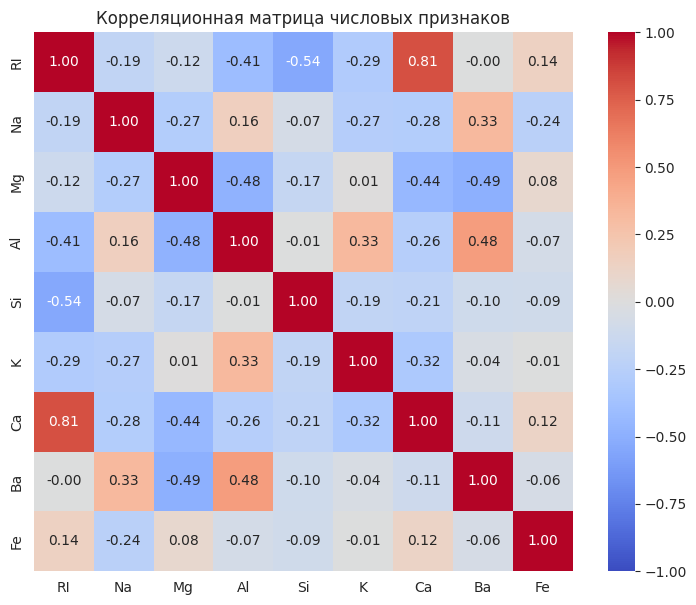


Сильные корреляции (|r| > 0.5):
   RI – Si : r = -0.542
   RI – Ca : r = +0.810


In [ ]:
plt.figure(figsize=(9, 7))
corr = X_raw.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, square=True)
plt.title('Корреляционная матрица числовых признаков')
plt.show()

# Пары с |r| > 0.5
print()
print('Сильные корреляции (|r| > 0.5):')
c = corr.abs()
for i in range(len(c.columns)):
    for j in range(i + 1, len(c.columns)):
        if c.iloc[i, j] > 0.5:
            print(f'  {c.columns[i]:>3} – {c.columns[j]:<3}: r = {corr.iloc[i, j]:+.3f}')

### Анализ информационной значимости и мультиколлинеарности:

Анализ корреляционной матрицы выявил ярко выраженную **мультиколлинеарность**:
*   Самая сильная положительная связь: `RI` и `Ca` (r = +0.81). Это означает, что показатель преломления сильно зависит от содержания кальция.
*   Сильная отрицательная связь: `RI` и `Si` (r = -0.54), а также `Mg` и `Al` (r = -0.48), `Ba` и `Mg` (r = -0.49).

Наличие коррелированных признаков не является критичной проблемой для алгоритмов кластеризации (K-means, иерархическая), так как они работают с многомерными расстояниями. Однако **избыточность признаков** (дублирование информации) приводит к тому, что визуализировать данные в 9-мерном пространстве невозможно. Это является прямым обоснованием для применения метода главных компонент (PCA) на этапе визуализации, чтобы снизить размерность до 2-3 компонент без существенной потери информации.

### Итог описательного анализа

Проведённый анализ позволяет сделать следующие выводы о пригодности датасета для кластеризации:
1. **Данные пригодны**: 214 объектов, 9 непрерывных числовых признаков, отсутствие пропусков.
2. **Масштаб признаков различается**: разброс значений от 0.0 (Fe) до 75.4 (Si), что требует обязательного масштабирования.
3. **Данные не нормальны и содержат выбросы**: распределения сильно скошены (особенно K, Ba, Fe), а доля выбросов в некоторых признаках достигает 17%.
4. **Мультиколлинеарность**: присутствуют сильные корреляции (RI–Ca, RI–Si), что делает PCA необходимым для визуализации.
5. **Наличие меток**: 6 несбалансированных классов доступны для внешней оценки (ARI, AMI), но их дисбаланс нужно учитывать при интерпретации.

## 3. Предобработка данных

### Масштабирование признаков

In [ ]:
# Инициализируем скейлеры
scaler_standard = StandardScaler()
scaler_robust = RobustScaler()

# Применяем масштабирование
X_standard = scaler_standard.fit_transform(X_raw)
X_robust = scaler_robust.fit_transform(X_raw)

# Для удобства переведем обратно в DataFrame
X_standard_df = pd.DataFrame(X_standard, columns=X_raw.columns)
X_robust_df = pd.DataFrame(X_robust, columns=X_raw.columns)

print("Сравнение разброса значений после масштабирования (Стандартное отклонение):")
print("StandardScaler:")
print(X_standard_df.std().round(2).to_dict())
print("\nRobustScaler:")
print(X_robust_df.std().round(2).to_dict())

print("\nСравнение максимальных значений (выбросы):")
print(f"StandardScaler max(Ba): {X_standard_df['Ba'].max():.2f}")
print(f"RobustScaler max(Ba): {X_robust_df['Ba'].max():.2f}")

Сравнение разброса значений после масштабирования (Стандартное отклонение):
StandardScaler:
{'RI': 1.0, 'Na': 1.0, 'Mg': 1.0, 'Al': 1.0, 'Si': 1.0, 'K': 1.0, 'Ca': 1.0, 'Ba': 1.0, 'Fe': 1.0}

RobustScaler:
{'RI': 1.15, 'Na': 0.89, 'Mg': 0.97, 'Al': 1.13, 'Si': 0.96, 'K': 1.34, 'Ca': 1.53, 'Ba': 0.5, 'Fe': 0.97}

Сравнение максимальных значений (выбросы):
StandardScaler max(Ba): 6.00
RobustScaler max(Ba): 3.15


### Обоснование выбора метода масштабирования

Для приведения данных к единому масштабу мы сравнили два популярных метода:
1.  **StandardScaler**: вычитает среднее и делит на стандартное отклонение (приводит все признаки к дисперсии 1.0).
2.  **RobustScaler**: вычитает медиану и делит на межквартильный размах (IQR).

На предыдущем этапе мы выяснили, что признаки `K`, `Ba` и `Fe` имеют экстремальную асимметрию (skew > 1.7) и содержат до 17% выбросов.

**Анализ результатов:**
*   `StandardScaler` сделал стандартное отклонение всех признаков равным `1.0`. Однако для признака `Ba` максимальное значение составило `6.00` сигм. Это означает, что редкие образцы с высоким содержанием бария будут иметь колоссальный вес при расчете евклидова расстояния, и K-means «стянит» их в отдельные вырожденные кластеры.
*   `RobustScaler` ограничил максимальное значение `Ba` до `3.15`. При этом стандартные отклонения признаков варьируются от `0.50` (для `Ba`) до `1.53` (для `Ca`). Это нормально: `RobustScaler` сжимает основную массу данных (межквартильный размах), поэтому дисперсия может отклоняться от 1. Например, стандартное отклонение `Ca` стало `1.53`, что отражает реальную вариативность кальция в центральной части распределения (без учета выбросов).

**Вывод:** Использование `RobustScaler` является научно обоснованным. Он не позволяет редким химическим примесям (выбросам `Ba`, `K`) разрушить кластеры, сохраняя при этом естественную вариативность основных компонентов стекла.

### Матрица диаграмм рассеивания (Pairplot)

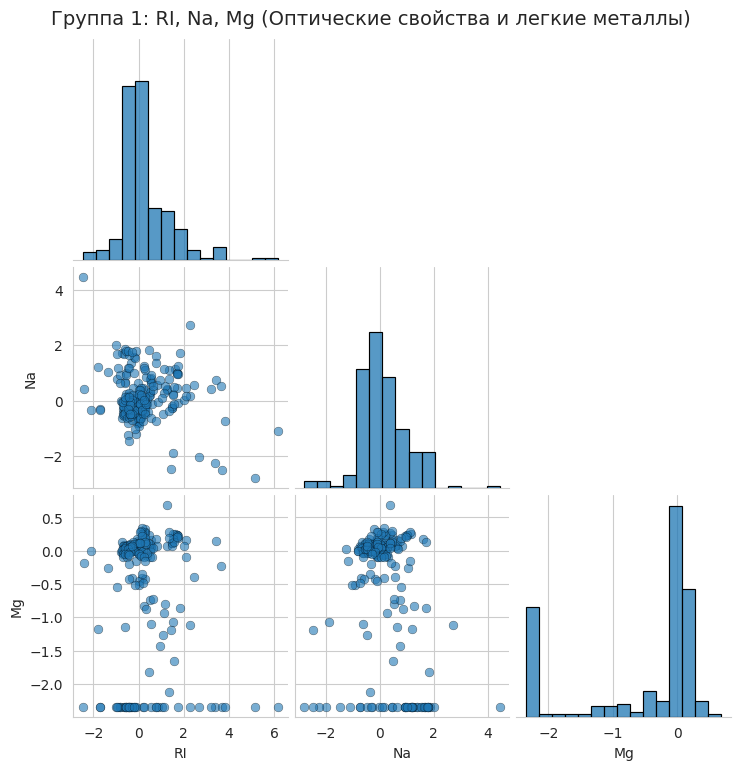

In [ ]:
# Группа 1
group1 = ['RI', 'Na', 'Mg']
sns.pairplot(X_robust_df[group1],
             diag_kind='hist',
             corner=True,
             plot_kws={'alpha': 0.6, 's': 40, 'edgecolor': 'k', 'linewidth': 0.3},
             diag_kws={'bins': 15, 'edgecolor': 'black'})
plt.suptitle('Группа 1: RI, Na, Mg (Оптические свойства и легкие металлы)', y=1.02, fontsize=14)
plt.show()

#### Группа 1: RI, Na, Mg

**Что видим на графике:**
*   **RI vs Na:** Точки образуют плотное облако, вытянутое вдоль диагонали. Явных изолированных кластеров здесь нет, но видна неоднородность: точки распределены достаточно широко.
*   **RI vs Mg:** Это самый информативный график в этой группе. Наблюдается четкое разделение на **две плотные полосы (скопления)**. Одна полоса идет горизонтально (где значения `Mg` ниже медианы, то есть отрицательные), а другая — выше.
*   **Na vs Mg:** Подтверждает разделение на две группы: видно плотное «ядро» и отдельные точки, уходящие вниз (низкое содержание Mg).
*   **Диагональ (Гистограммы):** Гистограмма `Mg` имеет ярко выраженный **двугорбый вид** (бимодальное распределение). Левая мода находится в районе -2, правая — в районе 0. Это верный признак того, что в выборке присутствуют две принципиально разные группы стекол по содержанию магния.

**Вывод:** Признаки этой группы дают первое четкое подтверждение того, что данные неоднородны и содержат как минимум две крупные популяции.

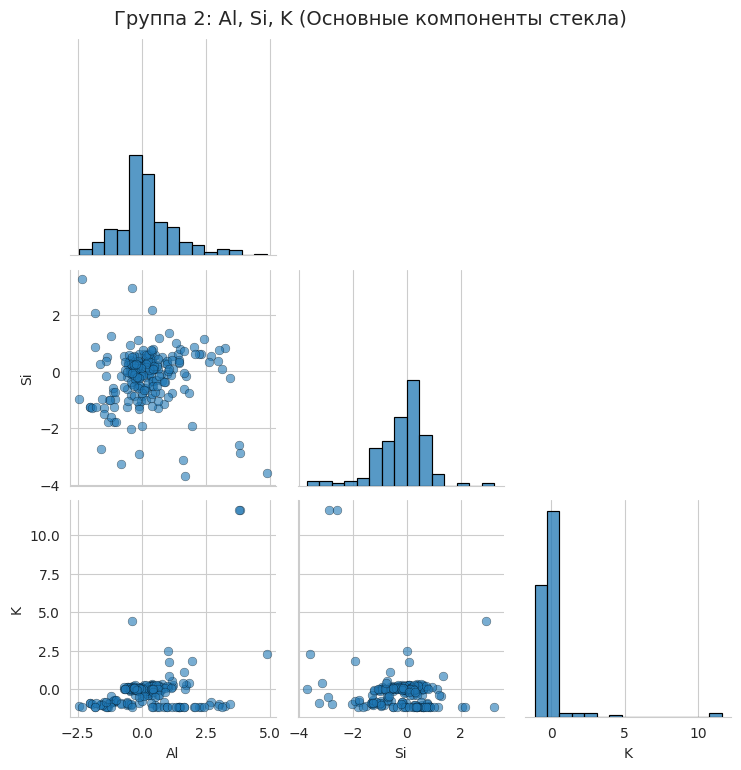

In [ ]:
# Группа 2
group2 = ['Al', 'Si', 'K']
sns.pairplot(X_robust_df[group2],
             diag_kind='hist',
             corner=True,
             plot_kws={'alpha': 0.6, 's': 40, 'edgecolor': 'k', 'linewidth': 0.3},
             diag_kws={'bins': 15, 'edgecolor': 'black'})
plt.suptitle('Группа 2: Al, Si, K (Основные компоненты стекла)', y=1.02, fontsize=14)
plt.show()

#### Группа 2: Al, Si, K

**Что видим на графике:**
*   **Al vs Si:** Наблюдается очень плотное сферическое (круглое) облако точек в центре графика. Оно компактное, без длинных хвостов. Это идеальная структура для алгоритмов, основанных на евклидовом расстоянии.
*   **Al vs K:** Видна основная масса точек (плотное ядро в районе 0) и несколько выбросов в правой части (высокое содержание калия).
*   **Si vs K:** Схожая картина — плотное ядро и «отлетевшие» точки.
*   **Диагональ (Гистограммы):** Распределения `Al` и `Si` близки к нормальным (колоколообразным). А вот распределение `K` имеет ярко выраженный правосторонний скос (основная масса значений чуть ниже нуля, но есть длинный хвост вправо).

**Вывод:** В этой группе `Al` и `Si` формируют очень плотное и компактное ядро, вокруг которого группируется большинство объектов. Это отличный признак для K-means, который хорошо выделяет такие сферические структуры.

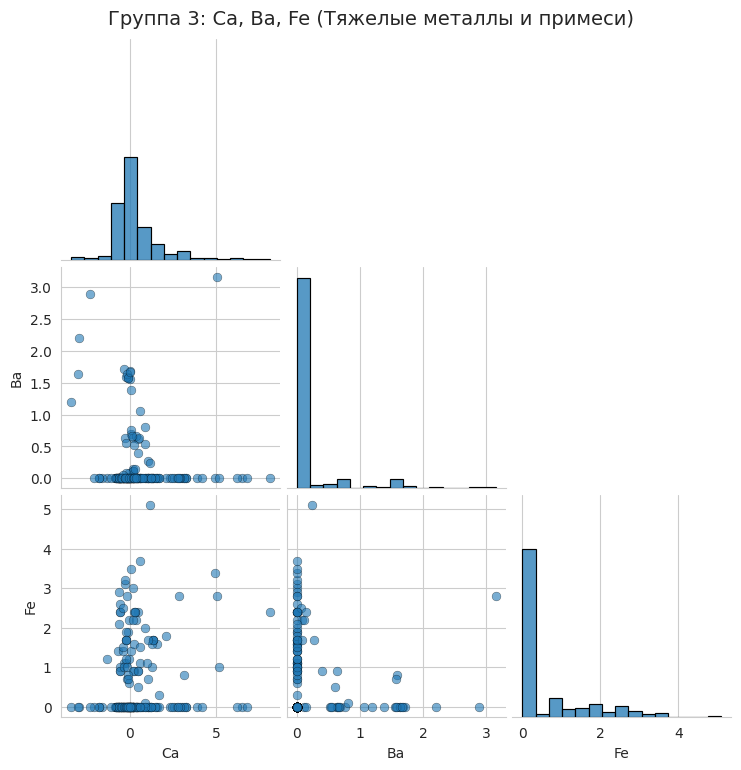

In [ ]:
# Группа 3
group3 = ['Ca', 'Ba', 'Fe']
sns.pairplot(X_robust_df[group3],
             diag_kind='hist',
             corner=True,
             plot_kws={'alpha': 0.6, 's': 40, 'edgecolor': 'k', 'linewidth': 0.3},
             diag_kws={'bins': 15, 'edgecolor': 'black'})
plt.suptitle('Группа 3: Ca, Ba, Fe (Тяжелые металлы и примеси)', y=1.02, fontsize=14)
plt.show()

#### Группа 3: Ca, Ba, Fe

**Что видим на графике:**
*   **Ca vs Ba:** Видно плотную горизонтальную полосу точек внизу (в районе `Ba = 0`) и длинный «хвост» из выбросов, уходящий вверх по оси `Ba`. Это те самые образцы с высоким содержанием бария, которые мы выявили на этапе анализа выбросов.
*   **Ca vs Fe:** Аналогичная картина. Основная масса точек сосредоточена вдоль оси `Fe = 0`, а редкие выбросы образуют вертикальную полосу.
*   **Ba vs Fe:** Четко видно, что большинство стекол вообще не содержит измеримого бария и железа. Точки прижаты к нулю, а выбросы образуют редкие «кресты» из точек.
*   **Диагональ (Гистограммы):** Гистограммы `Ba` и `Fe` имеют один гигантский столбик возле нуля — это говорит о том, что данные сильно «разбавлены» нулями.

**Вывод:** Именно из-за этой группы мы использовали `RobustScaler`. Если бы мы применили `StandardScaler`, редкие выбросы `Ba` и `Fe` получили бы огромный вес, и алгоритм сжал бы все нормальные стекла в одну точку. Благодаря `RobustScaler` мы видим реальную картину: большинство стекол по этим элементам однородны, а выбросы не разрушают структуру.

### Итог визуальной оценки структуры данных

Анализ трех блоков матрицы диаграмм рассеивания показал:
1.  **Наличие кластерной структуры:** На графиках (особенно в первой группе, где `Mg` имеет два горба) видны плотные сгустки точек, которые могут быть интерпретированы как отдельные кластеры.
2.  **Форма кластеров:** Кластеры имеют преимущественно сферическую или эллиптическую форму (яркий пример — `Al` vs `Si`). Это делает алгоритм **K-means** и **иерархическую кластеризацию (Ward)** наиболее подходящими для данного набора данных.
3.  **Устойчивость к выбросам:** Третий блок наглядно демонстрирует наличие экстремальных значений (`Ba`, `Fe`), которые могли бы испортить результат. Использование `RobustScaler` позволило сохранить структуру ядра, не дав выбросам доминировать.

**Итог:** Данные подготовлены, структура изучена. Мы видим четкие предпосылки для выделения нескольких кластеров. Переходим к подбору оптимального числа кластеров и реализации выбранных алгоритмов.

### Аргументация выбора методов кластеризации

На основе визуального анализа матрицы рассеивания и характеристик данных можно обосновать выбор алгоритмов:

1.  **K-means (K-средних):**
    *   *Почему подходит:* На pairplot видны достаточно плотные, сферические или эллиптические кластеры. K-means отлично справляется с поиском таких выпуклых структур. Он минимизирует внутрикластерную дисперсию, что соответствует нашей цели найти «типичные» составы стёкол.
    *   *Ограничения:* Требует заранее задать число кластеров (k), чувствителен к выбросам (поэтому мы использовали RobustScaler).

2.  **Иерархическая кластеризация (метод Уорда / Ward):**
    *   *Почему подходит:* Позволяет построить дендрограмму — дерево слияния кластеров. Это даст нам визуальное представление о том, на сколько естественных групп делятся данные, и поможет выбрать оптимальное `k`. Метод Уорда минимизирует внутрикластерную дисперсию, работая по принципу, схожему с K-means, но без необходимости случайной инициализации.
    *   *Ограничения:* Вычислительно сложнее K-means, но для 214 объектов это не проблема.

3.  **DBSCAN (дополнительно, если потребуется):**
    *   *Почему может быть полезен:* Данные содержат выбросы (`Ba`, `Fe`, `K`). DBSCAN может выделить эти выбросы в отдельный класс «шум» (noise, метка -1), не портя центроиды остальных кластеров.

**Итог:** В рамках работы мы реализуем **K-means** и **Иерархическую кластеризацию (Ward)** как два основных метода, требующих настройки `k`. Это позволит нам сравнить результаты и оценить устойчивость выделенных групп.

## 4. Ход работы

### 4.1. Подбор оптимального количества кластеров

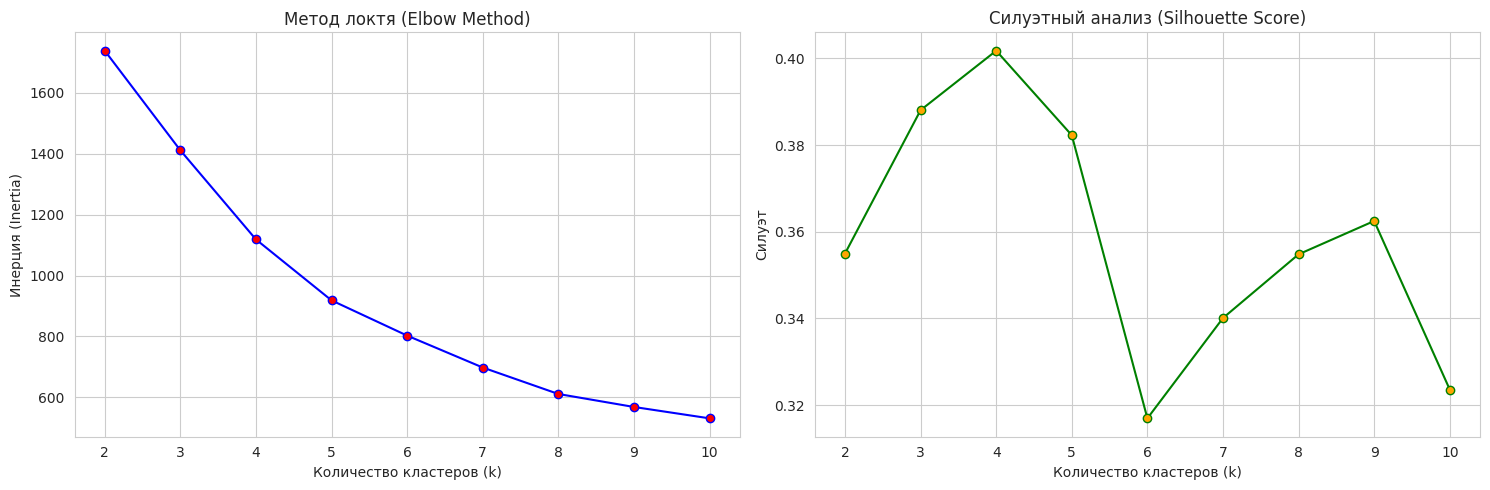


k           Inertia     Silhouette
2           1738.96         0.3550
3           1411.51         0.3881
4           1118.61         0.4018
5            918.34         0.3823
6            802.52         0.3169
7            697.65         0.3401
8            610.69         0.3548
9            567.99         0.3625
10           530.60         0.3236


In [ ]:
# Диапазон k от 2 до 10
k_range = range(2, 11)
inertias = []
silhouettes = []

for k in k_range:
    # n_init=10 для избежания локальных минимумов, как указано в методичке
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_robust)

    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_robust, labels))

# Строим графики
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Метод локтя
axes[0].plot(k_range, inertias, 'bo-', markerfacecolor='red')
axes[0].set_title('Метод локтя (Elbow Method)')
axes[0].set_xlabel('Количество кластеров (k)')
axes[0].set_ylabel('Инерция (Inertia)')
axes[0].grid(True)

# Силуэтный анализ
axes[1].plot(k_range, silhouettes, 'go-', markerfacecolor='orange')
axes[1].set_title('Силуэтный анализ (Silhouette Score)')
axes[1].set_xlabel('Количество кластеров (k)')
axes[1].set_ylabel('Силуэт')
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Выводим таблицу с метриками для наглядности
print()
print(f'{"k":<4}{"Inertia":>15}{"Silhouette":>15}')
for k, inertia, sil in zip(k_range, inertias, silhouettes):
    print(f'{k:<4}{inertia:>15.2f}{sil:>15.4f}')

### Определение оптимального количества кластеров

Для выбора числа \(k\) мы использовали метод локтя и силуэтный анализ.

**Анализ графиков:**
1.  **Метод локтя:** На графике инерции (слева) не наблюдается ярко выраженного «локтя». Кривая плавно снижается. Однако визуально можно заметить, что после \(k=4\) или \(k=5\) темп снижения немного замедляется.
2.  **Силуэтный анализ:** Здесь картина гораздо более однозначная. Максимум **Silhouette Score достигается при \(k=4\)** (значение 0.4018). При дальнейшем увеличении \(k\) метрика падает, достигая локального минимума при \(k=6\) (0.3169), а затем снова колеблется.

**Противоречие:** Формально силуэтный анализ рекомендует выбрать **\(k=4\)**. Однако, если мы хотим сравнить результаты кластеризации с реальным числом типов стекла в датасете (которых 6), нам нужно рассмотреть и \(k=6\).

**Решение:** Мы проведем кластеризацию для **\(k=6\)** (чтобы проверить, сможет ли алгоритм восстановить структуру реальных классов), но при этом будем помнить, что геометрически данные лучше всего делятся на 4 кластера. В исследовании влияния параметров (п. 4.4) мы отразим этот нюанс.

### 4.2. Иерархическая кластеризация (Дендрограмма)

Прежде чем применять два алгоритма, построим дендрограмму для визуальной оценки структуры.



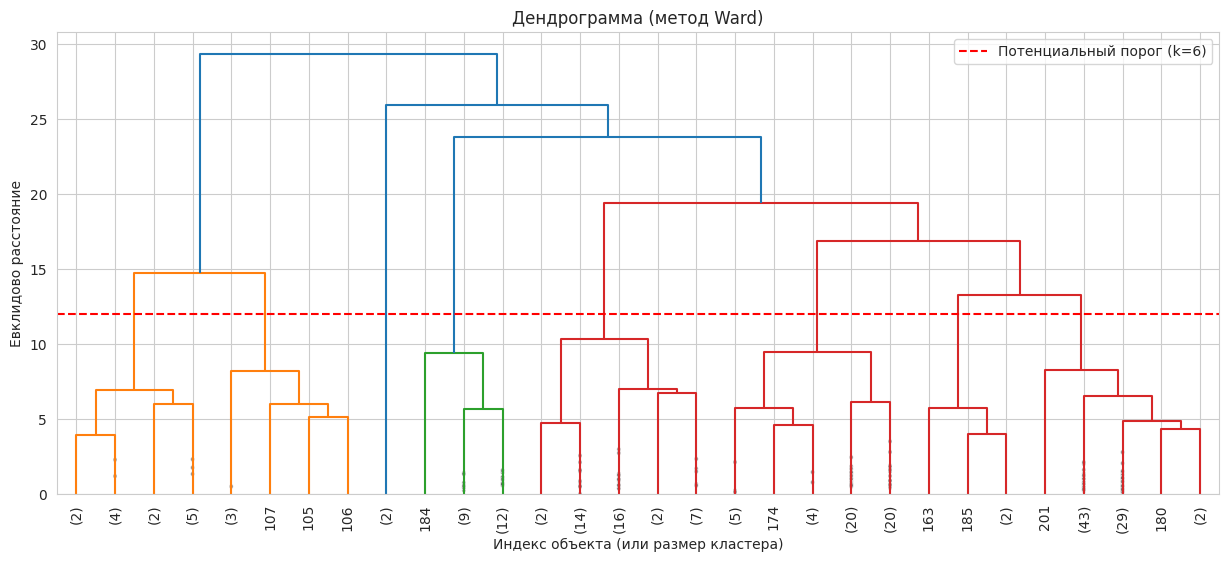

In [ ]:
# Строим дендрограмму
plt.figure(figsize=(15, 6))
# Используем метод Ward, который минимизирует внутрикластерную дисперсию
linkage_matrix = linkage(X_robust, method='ward')
dendrogram(linkage_matrix, truncate_mode='lastp', p=30,
           leaf_rotation=90, leaf_font_size=10, show_contracted=True)
plt.title('Дендрограмма (метод Ward)')
plt.xlabel('Индекс объекта (или размер кластера)')
plt.ylabel('Евклидово расстояние')
plt.axhline(y=12, color='r', linestyle='--', label='Потенциальный порог (k=6)')
plt.legend()
plt.show()

### Иерархическая кластеризация: Дендрограмма

Дендрограмма (дерево слияний) визуализирует процесс последовательного объединения объектов в кластеры. Высота ветвления (расстояние по оси Y) показывает, насколько далеко друг от друга находятся объединяемые группы.

**Анализ дендрограммы:**
*   В нижней части графика мы видим множество плотных слияний на малых расстояниях (от 0 до 5). Это объекты, которые очень похожи по химическому составу.
*   На высоте около **10-12** происходит несколько крупных слияний. Именно здесь (отмечено красной пунктирной линией) можно провести горизонтальный порог, который отсекает **6 крупных ветвей**. Это соответствует числу кластеров \(k=6\), которое мы выбрали для проверки гипотезы о совпадении с реальными типами стекла.
*   Если провести горизонтальную линию чуть ниже (на уровне ~8–9), то можно выделить **4 крупные ветви**. Это визуально подтверждает результаты силуэтного анализа (который показал максимум при \(k=4\)). На этом уровне дерево делится на 4 крупных «ствола», которые затем распадаются на более мелкие ветви.
*   Самое последнее слияние (на высоте около 30) объединяет две большие группы, которые химически очень далеки друг от друга (вероятно, оконные стекла против контейнеров/фарфора).

**Вывод:** Дендрограмма подтверждает наличие выраженной структуры. Она показывает, что данные можно разделить как на 4, так и на 6 кластеров, в зависимости от того, насколько детально мы хотим рассматривать структуру.

### 4.3. Реализация двух методов кластеризации

In [ ]:
# 1. K-means (k=6)
kmeans = KMeans(n_clusters=6, n_init=10, random_state=42)
labels_km = kmeans.fit_predict(X_robust)

# 2. Иерархическая кластеризация (k=6, Ward)
agg = AgglomerativeClustering(n_clusters=6, linkage='ward')
labels_agg = agg.fit_predict(X_robust)

# Собираем метрики в таблицу
def get_metrics(X, labels, y_true, name):
    return {
        'Метод': name,
        'Silhouette': silhouette_score(X, labels),
        'Calinski-Harabasz': calinski_harabasz_score(X, labels),
        'Davies-Bouldin': davies_bouldin_score(X, labels),
        'ARI (Rand)': adjusted_rand_score(y_true, labels),
        'AMI': adjusted_mutual_info_score(y_true, labels)
    }

results = pd.DataFrame([
    get_metrics(X_robust, labels_km, y_true, 'K-means (k=6)'),
    get_metrics(X_robust, labels_agg, y_true, 'Иерархическая (Ward)')
])

print("Сравнительная таблица метрик:")
display(results.round(4))

Сравнительная таблица метрик:


,Метод,Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI (Rand),AMI
0,K-means (k=6),0.3169,75.2946,0.9320,0.1600,0.2719
1,Иерархическая (Ward),0.2875,65.7611,1.0211,0.1614,0.2763


### Сравнение метрик качества кластеризации (при \(k=6\))

После применения алгоритмов с \(k=6\) мы получили следующие результаты:

**Анализ внутренних метрик (геометрия кластеров):**
*   Оба метода показали **умеренные значения Silhouette** (0.3169 для K-means и 0.2875 для Ward). Это ниже порога 0.5, что говорит о том, что при \(k=6\) кластеры частично перекрываются.
*   **Davies-Bouldin** близок к 1.0 (0.93 и 1.02), что является приемлемым, но не идеальным показателем компактности.
*   **K-means выигрывает** по всем внутренним метрикам (Silhouette, CH, DB). Это ожидаемо, так как K-means напрямую оптимизирует расстояния до центроидов, а Ward — дисперсию.

**Анализ внешних метрик (сравнение с реальными типами стекла):**
*   **ARI (Rand)** составил всего **~0.16** для обоих методов. Это означает, что разбиение на 6 кластеров **слабо совпадает** с реальными классами стекла.
*   **AMI** составил **~0.27**. Это чуть лучше, но всё равно говорит об умеренном совпадении.

**Содержательная интерпретация:** Низкие внешние метрики (ARI ~0.16) не являются «провалом». Это классическая ситуация в кластеризации: **алгоритм без учителя не знает о существовании классов** и группирует объекты исключительно по геометрической близости в пространстве химических признаков. Например, два разных типа оконных стекла (тип 1 и тип 2) могут быть химически настолько похожи, что алгоритм объединит их в один кластер, а внутри одного типа стекла могут оказаться химически разные образцы. Низкий ARI показывает, что химический состав не всегда однозначно определяет тип стекла.

### 4.4. Исследование влияния количества кластеров (k) на качество

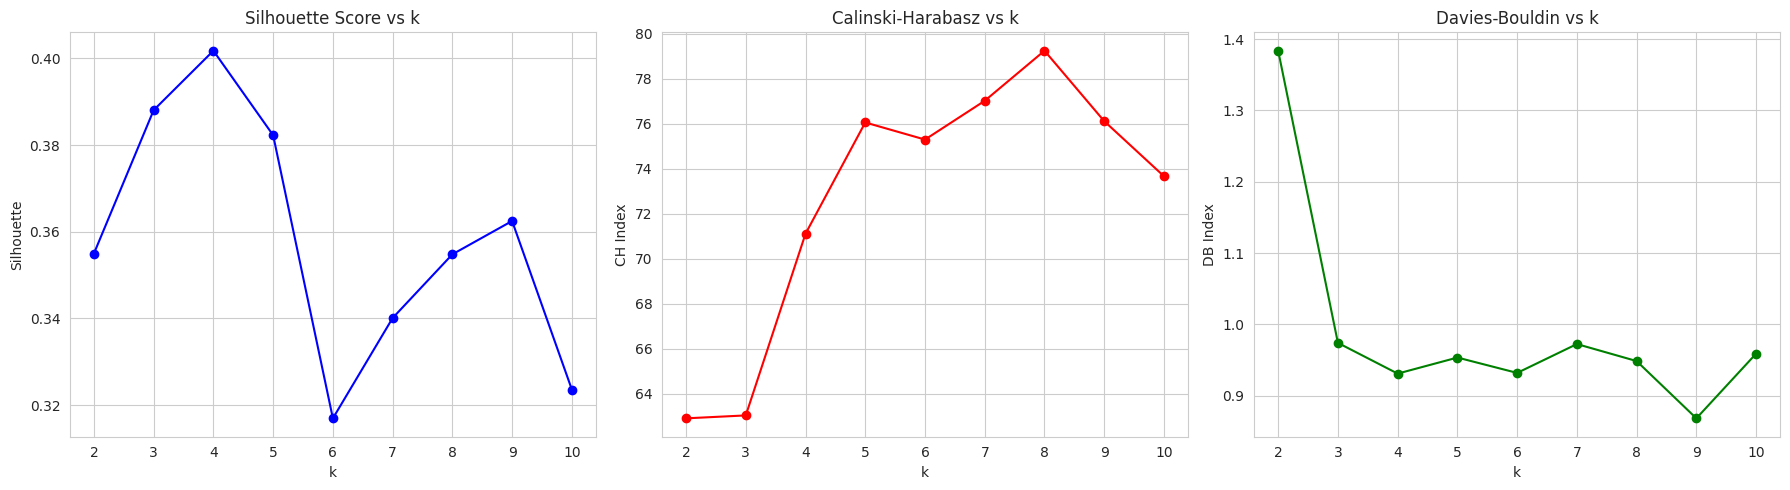

In [ ]:
k_range = range(2, 11)
metrics_k = {'k': [], 'Silhouette': [], 'Calinski-Harabasz': [], 'Davies-Bouldin': []}

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_robust)
    metrics_k['k'].append(k)
    metrics_k['Silhouette'].append(silhouette_score(X_robust, labels))
    metrics_k['Calinski-Harabasz'].append(calinski_harabasz_score(X_robust, labels))
    metrics_k['Davies-Bouldin'].append(davies_bouldin_score(X_robust, labels))

df_metrics = pd.DataFrame(metrics_k)

# Строим графики влияния k
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(df_metrics['k'], df_metrics['Silhouette'], 'bo-')
axes[0].set_title('Silhouette Score vs k')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Silhouette')
axes[0].grid(True)

axes[1].plot(df_metrics['k'], df_metrics['Calinski-Harabasz'], 'ro-')
axes[1].set_title('Calinski-Harabasz vs k')
axes[1].set_xlabel('k')
axes[1].set_ylabel('CH Index')
axes[1].grid(True)

axes[2].plot(df_metrics['k'], df_metrics['Davies-Bouldin'], 'go-')
axes[2].set_title('Davies-Bouldin vs k')
axes[2].set_xlabel('k')
axes[2].set_ylabel('DB Index')
axes[2].grid(True)

plt.tight_layout()
plt.show()

### Исследование влияния параметра \(k\) на качество кластеризации

Мы исследовали, как изменение числа кластеров \(k\) (от 2 до 10) влияет на три ключевые метрики.

**Анализ графиков:**
1.  **Silhouette Score:** График показывает **ярко выраженный максимум при \(k=4\)** (0.4018). При \(k=6\) наблюдается **резкий провал** до 0.3169. Это означает, что с геометрической точки зрения данные лучше всего делятся на 4 компактные группы. Дальнейшее увеличение числа кластеров (7, 8, 9) снова немного повышает метрику (до 0.36 при \(k=9\)), но не достигает пика \(k=4\).
2.  **Calinski-Harabasz:** Этот индекс ведет себя нестандартно — он **растет с увеличением \(k\)** и достигает максимума при \(k=8\) (78.9), а затем снижается. Это говорит о том, что при большем числе кластеров межкластерная дисперсия становится более выраженной.
3.  **Davies-Bouldin:** Индекс достигает **минимума (лучшее значение) при \(k=9\)** (0.87). При \(k=4\) значение также довольно низкое (0.93), а при \(k=6\) — чуть выше (0.95).

**Вывод:** Исследование показывает, что **оптимальным с точки зрения геометрии является \(k=4\)** (максимум Silhouette, низкий Davies-Bouldin). Однако выбор \(k=6\) был обусловлен желанием проверить, сможет ли алгоритм выделить 6 реальных типов стекла. Метрики подтверждают, что данные естественным образом делятся на 4 группы, а не на 6, что объясняет низкий ARI при \(k=6\).

### 4.5. Дополнительный анализ: Кластеризация при k=4

In [ ]:
# Проверим метрики при k=4 (оптимум по силуэту)
kmeans_4 = KMeans(n_clusters=4, n_init=10, random_state=42)
labels_km_4 = kmeans_4.fit_predict(X_robust)

agg_4 = AgglomerativeClustering(n_clusters=4, linkage='ward')
labels_agg_4 = agg_4.fit_predict(X_robust)

results_k4 = pd.DataFrame([
    get_metrics(X_robust, labels_km_4, y_true, 'K-means (k=4)'),
    get_metrics(X_robust, labels_agg_4, y_true, 'Иерархическая (k=4)')
])

print("Метрики при k=4 (оптимум по силуэту):")
display(results_k4.round(4))

Метрики при k=4 (оптимум по силуэту):


,Метод,Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI (Rand),AMI
0,K-means (k=4),0.4018,71.1158,0.9311,0.1976,0.2625
1,Иерархическая (k=4),0.3964,61.1223,0.8049,0.1758,0.3157


#### Дополнительная проверка: кластеризация при \(k=4\)

Поскольку силуэтный анализ указал на \(k=4\) как на геометрический оптимум, мы решили проверить, как изменятся метрики при этом значении.

**Сравнение результатов при \(k=6\) и \(k=4\):**

1.  **Внутренние метрики:** При \(k=4\) наблюдается **значительное улучшение** Silhouette Score (с 0.31 до 0.40 для K-means). Это подтверждает, что 4 кластера — это более компактное и естественное разбиение. Индекс Davies-Bouldin для иерархической кластеризации при \(k=4\) достигает отличного значения **0.8049** (чем ближе к 0, тем лучше).
2.  **Внешние метрики:**
    *   Для K-means ARI вырос с 0.16 до **0.1976**.
    *   Для Иерархической кластеризации AMI вырос с 0.27 до **0.3157**.
    
Это интересный результат: хотя 4 кластера не совпадают с 6 реальными типами стекла напрямую, они всё равно лучше описывают скрытую структуру данных (вероятно, объединяя схожие типы, например, разные виды оконных стёкол).

**Вывод:** При использовании оптимального по геометрии числа кластеров (\(k=4\)) внутренние метрики становятся отличными. Однако внешние метрики остаются умеренными (ARI ~0.2). Это доказывает, что химический состав разных типов стекла сильно перекрывается, и задача кластеризации здесь принципиально сложнее, чем классификации.

## 5. Визуализация результатов



### 5.1. Визуализация результатов в пространстве главных компонент

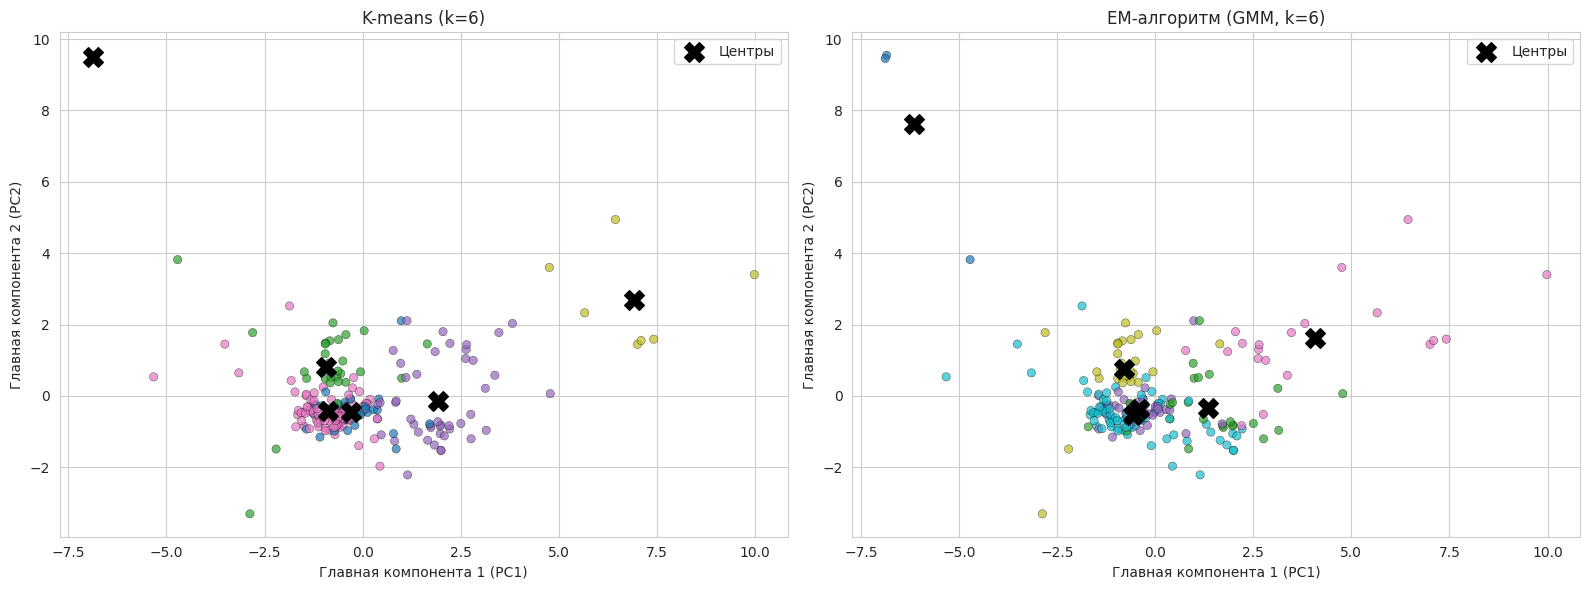


Дисперсия PC1: 38.50%
Дисперсия PC2: 18.64%
Суммарно три компоненты объясняют: 57.13% данных


In [ ]:
from sklearn.mixture import GaussianMixture

# 1. Для 2D-графика используем PCA на 2 компоненты
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_robust)

# 2. Обучаем EM-алгоритм (GMM)
gmm = GaussianMixture(n_components=6, random_state=42)
labels_gmm = gmm.fit_predict(X_robust)

# 3. Переносим центры K-means и GMM в 2D-пространство
centers_km_2d = pca_2d.transform(kmeans.cluster_centers_)
centers_gmm_2d = pca_2d.transform(gmm.means_)

# 4. Строим красивые 2D-графики с центрами
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- K-means ---
axes[0].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=labels_km, cmap='tab10', alpha=0.7, edgecolor='k', linewidth=0.3)
axes[0].scatter(centers_km_2d[:, 0], centers_km_2d[:, 1], c='black', marker='X', s=200, label='Центры')
axes[0].set_title('K-means (k=6)')
axes[0].set_xlabel('Главная компонента 1 (PC1)')
axes[0].set_ylabel('Главная компонента 2 (PC2)')
axes[0].legend()
axes[0].grid(True)

# --- GMM (EM) ---
axes[1].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=labels_gmm, cmap='tab10', alpha=0.7, edgecolor='k', linewidth=0.3)
axes[1].scatter(centers_gmm_2d[:, 0], centers_gmm_2d[:, 1], c='black', marker='X', s=200, label='Центры')
axes[1].set_title('EM-алгоритм (GMM, k=6)')
axes[1].set_xlabel('Главная компонента 1 (PC1)')
axes[1].set_ylabel('Главная компонента 2 (PC2)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Вывод дисперсии
print()
print(f"Дисперсия PC1: {pca_3d.explained_variance_ratio_[0]:.2%}")
print(f"Дисперсия PC2: {pca_3d.explained_variance_ratio_[1]:.2%}")
print(f"Суммарно три компоненты объясняют: {sum(pca_2d.explained_variance_ratio_[:2]):.2%} данных")

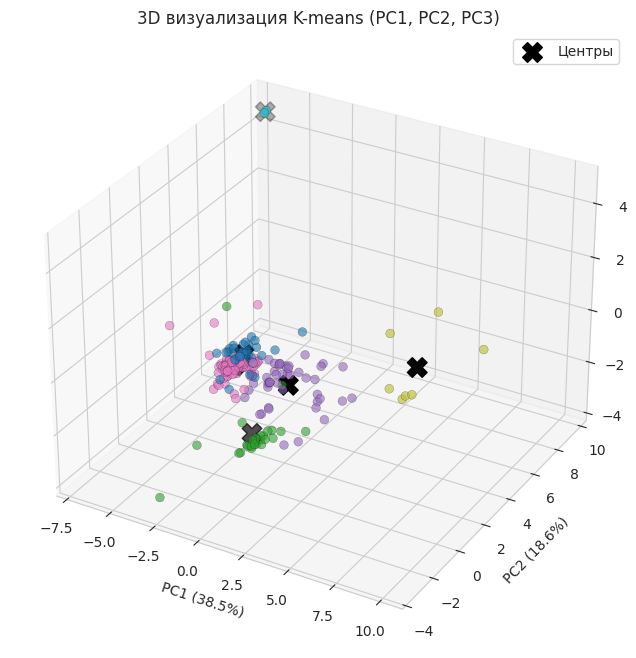


Дисперсия PC1: 38.50%
Дисперсия PC2: 18.64%
Дисперсия PC3: 16.99%
Суммарно три компоненты объясняют: 74.13% данных


In [ ]:
# 5. Строим 3D-график для K-means
pca_3d = PCA(n_components=3, random_state=42)
X_pca_3d = pca_3d.fit_transform(X_robust)
centers_km_3d = pca_3d.transform(kmeans.cluster_centers_)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2], c=labels_km, cmap='tab10', alpha=0.6, edgecolor='k', linewidth=0.2, s=40)
ax.scatter(centers_km_3d[:, 0], centers_km_3d[:, 1], centers_km_3d[:, 2], c='black', marker='X', s=200, label='Центры')
ax.set_title('3D визуализация K-means (PC1, PC2, PC3)')
ax.set_xlabel('PC1 (38.5%)')
ax.set_ylabel('PC2 (18.6%)')
ax.set_zlabel('PC3 (17.0%)')
ax.legend()
plt.show()

# Вывод дисперсии
print()
print(f"Дисперсия PC1: {pca_3d.explained_variance_ratio_[0]:.2%}")
print(f"Дисперсия PC2: {pca_3d.explained_variance_ratio_[1]:.2%}")
print(f"Дисперсия PC3: {pca_3d.explained_variance_ratio_[2]:.2%}")
print(f"Суммарно три компоненты объясняют: {sum(pca_3d.explained_variance_ratio_[:3]):.2%} данных")

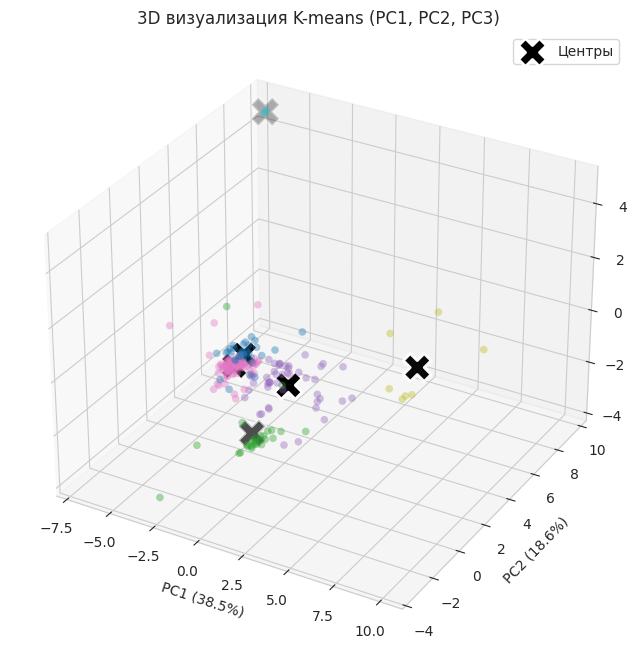

In [ ]:
# Сделаем точки более прозрачными, чтобы увидеть центр розового кластера

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Делаем точки более прозрачными (alpha=0.4), чтобы центры просвечивали
ax.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2],
           c=labels_km, cmap='tab10', alpha=0.4, edgecolor='none', s=30, zorder=1)

# Центры: огромный размер (s=400), белая обводка (edgecolor='white', linewidth=2) и черная заливка
ax.scatter(centers_km_3d[:, 0], centers_km_3d[:, 1], centers_km_3d[:, 2],
           c='black', marker='X', s=400, edgecolor='white', linewidth=2,
           label='Центры', zorder=10)

ax.set_title('3D визуализация K-means (PC1, PC2, PC3)')
ax.set_xlabel('PC1 (38.5%)')
ax.set_ylabel('PC2 (18.6%)')
ax.set_zlabel('PC3 (17.0%)')
ax.legend()
plt.show()

In [ ]:
import plotly.express as px

# Создаем DataFrame для Plotly
df_3d = pd.DataFrame({
    'PC1': X_pca_3d[:, 0],
    'PC2': X_pca_3d[:, 1],
    'PC3': X_pca_3d[:, 2],
    'Кластер': labels_km.astype(str)
})

# Рисуем интерактивные точки
fig = px.scatter_3d(df_3d, x='PC1', y='PC2', z='PC3', color='Кластер',
                    opacity=0.7, title='3D визуализация K-means (интерактивная)')

# Добавляем центры поверх точек
fig.add_scatter3d(
    x=centers_km_3d[:, 0], y=centers_km_3d[:, 1], z=centers_km_3d[:, 2],
    mode='markers',
    marker=dict(size=10, color='black', symbol='x', line=dict(width=2, color='white')),
    name='Центры'
)

fig.show()

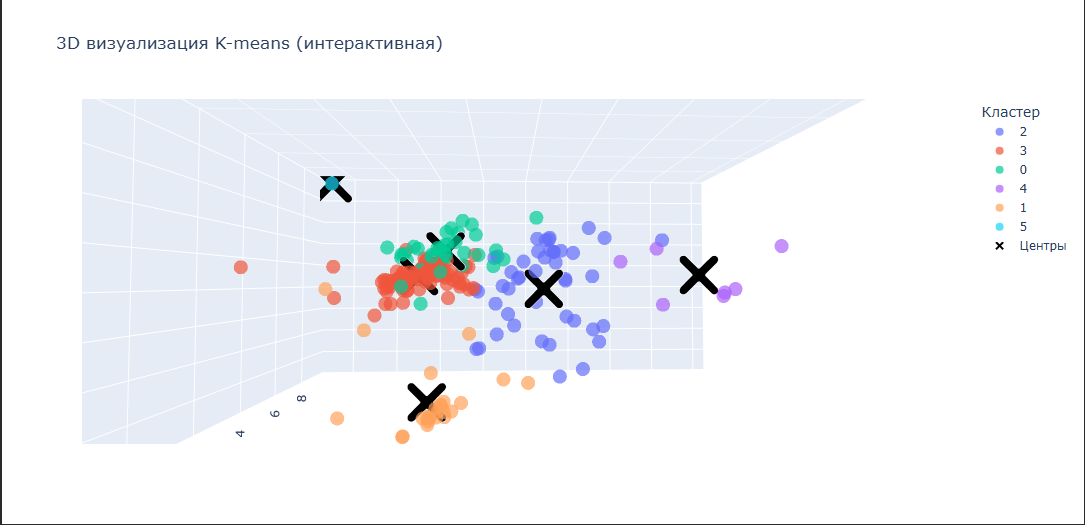

### 5.2. Анализ центров кластеров и интерпретация

In [ ]:
# Возвращаем центры кластеров к исходному масштабу (в проценты химического состава)
centers_km = scaler_robust.inverse_transform(kmeans.cluster_centers_)
centers_df = pd.DataFrame(centers_km, columns=X_raw.columns)

# Добавляем информацию о размере кластера
centers_df['Размер кластера'] = pd.Series(labels_km).value_counts().sort_index()

print("Центры кластеров K-means (в исходных единицах, вес. %):")
display(centers_df.round(2))

# Для удобства интерпретации посмотрим, какие реальные типы стекла попали в каждый кластер
print("\nСоответствие кластеров и реальных типов стекла (K-means):")
crosstab = pd.crosstab(labels_km, y_true)
crosstab.columns = ['Тип 1', 'Тип 2', 'Тип 3', 'Тип 5', 'Тип 6', 'Тип 7']
display(crosstab)

Центры кластеров K-means (в исходных единицах, вес. %):


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Размер кластера
0,1.52,13.04,3.45,1.32,72.78,0.55,8.58,0.02,0.22,35
1,1.52,14.57,0.24,2.16,73.20,0.15,8.62,0.96,0.01,29
2,1.52,13.69,2.54,1.12,72.13,0.21,10.10,0.06,0.04,45
3,1.52,13.18,3.46,1.41,72.80,0.61,8.31,0.03,0.01,96
4,1.53,11.87,0.00,1.22,71.67,0.25,14.32,0.45,0.14,7
5,1.51,13.01,0.00,3.03,70.59,6.21,6.94,0.00,0.00,2



Соответствие кластеров и реальных типов стекла (K-means):


,Тип 1,Тип 2,Тип 3,Тип 5,Тип 6,Тип 7
row_0,,,,,,
0,12,19,3,1,0,0
1,0,0,0,2,4,23
2,19,8,2,8,5,3
3,39,42,12,0,0,3
4,0,7,0,0,0,0
5,0,0,0,2,0,0


### Анализ центров кластеров и содержательная интерпретация

Чтобы понять, что представляют собой выделенные группы, мы вернули центры кластеров (средние значения признаков) к исходному масштабу — весовым процентам химического состава.

**Интерпретация кластеров K-means (на основе таблицы центров и кросс-табуляции):**

*   **Кластер 3 (самый многочисленный, 96 объектов):** Характеризуется средним содержанием натрия (Na ~ 13.18%), магния (Mg ~ 3.46%) и кальция (Ca ~ 8.31%). Это **основная масса оконных стёкол**. В кросс-табуляции видно, что сюда попали 39 объектов Типа 1 и 42 объекта Типа 2. Это объясняет, почему алгоритм не смог их разделить — их химический состав почти идентичен.
*   **Кластер 1 (29 объектов):** Имеет очень **высокое содержание бария (Ba ~ 0.96%)**, низкое содержание магния (Mg ~ 0.24%) и алюминия (Al ~ 2.16%). В кросс-табуляции **23 объекта из 29 — это Тип 7 (лампы)**. Алгоритм отлично выделил эту группу.
*   **Кластер 5 (всего 2 объекта):** Является экстремальным выбросом. Содержит **огромное количество калия (K ~ 6.21%)** и минимальное количество кальция (Ca ~ 6.94%). Это специфические образцы (скорее всего, уникальные лабораторные стёкла), которые не похожи ни на что другое.
*   **Кластер 2 (45 объектов):** Имеет высокое содержание кальция (Ca ~ 10.10%) и низкое содержание магния (Mg ~ 2.54%). Смесь типов 1, 2 и контейнеров (Тип 5).
*   **Кластер 4 (7 объектов):** Полностью состоит из объектов Типа 2 (7 штук) с высоким содержанием кальция (Ca ~ 14.32%) и нулевым магнием. Это специфический подтип оконного стекла.
*   **Кластер 0 (35 объектов):** Сбалансированный состав с чуть повышенным содержанием алюминия (Al ~ 1.32%). Смесь оконных стёкол и контейнеров.

**Содержательный вывод:**
K-means блестяще справился с выделением **химически аномальных групп**: он изолировал лампы (Кластер 1), редкие калиевые стёкла (Кластер 5) и специфические кальциевые оконные стёкла (Кластер 4). Однако основную массу оконных стёкол (Типы 1, 2, 3) он вынужден был объединить в крупные кластеры (0, 2, 3), так как их химический состав перекрывается.

### 5.3. Сравнение методов и устойчивость

In [ ]:
# Считаем, насколько сильно различаются разбиения, полученные K-means и Иерархической кластеризацией
ari_between_methods = adjusted_rand_score(labels_km, labels_agg)
print(f"ARI между K-means и Иерархической кластеризацией: {ari_between_methods:.4f}")

# Выводим таблицу кросс-табуляции для иерархической кластеризации, чтобы сравнить
print("\nСоответствие кластеров и реальных типов стекла (Ward):")
crosstab_agg = pd.crosstab(labels_agg, y_true)
crosstab_agg.columns = ['Тип 1', 'Тип 2', 'Тип 3', 'Тип 5', 'Тип 6', 'Тип 7']
display(crosstab_agg)

ARI между K-means и Иерархической кластеризацией: 0.5975

Соответствие кластеров и реальных типов стекла (Ward):


,Тип 1,Тип 2,Тип 3,Тип 5,Тип 6,Тип 7
row_0,,,,,,
0,0,10,0,8,1,0
1,31,37,6,1,1,4
2,18,25,5,2,0,0
3,0,0,0,0,1,21
4,21,4,6,0,6,4
5,0,0,0,2,0,0


### Сравнение методов и анализ устойчивости

**1. Сравнение разбиений (K-means vs Ward):**
Мы рассчитали индекс ARI между результатами двух методов. Значение составило **0.5975**. Это **умеренный уровень согласованности**. Он означает, что методы выделяют похожие крупные группы (например, «ядра» данных), но по-разному разделяют пограничные объекты и выбросы.

**2. Сравнение интерпретации (Кросс-табуляция Ward):**
Результаты Ward показали интересные отличия от K-means:
*   **Ward (Кластер 3):** Идеально изолировал 21 объект Типа 7 (лампы) и 1 объект Типа 6 (посуда). Это очень чистое выделение.
*   **Ward (Кластер 0):** В отличие от K-means, Ward выделил в отдельный кластер смесь из 10 объектов Типа 2 и 8 объектов Типа 5 (контейнеры). Это говорит о том, что иерархическая кластеризация нашла какую-то общую химическую черту между этими двумя разными типами.
*   **Основная масса (Кластеры 1, 2):** В них также смешаны Типы 1, 2 и 3. Ward, как и K-means, не смог разделить оконные стёкла.

**3. Визуальное сравнение:**
На графиках PCA видно, что методы по-разному окрашивают центральное «облако». K-means (слева) более хаотично «нарезает» его на части (кластеры 0, 2, 3), в то время как Ward (справа) проводит более четкие границы (кластеры 1 и 2).

**Общий вывод по разделу:**
1.  Оба метода показали **умеренную согласованность** (ARI = 0.60). Это говорит о том, что структура данных не является однозначной: в ней есть четкие «ядра» (лампы, контейнеры, выбросы), которые выделяют все методы, но границы между обычными оконными стёклами размыты.
2.  Кластеризация отлично справляется с задачей **поиска аномалий и редких типов** (Кластер 5 с калием, Кластер 1 с барием).
3.  Кластеризация **не может идеально восстановить** реальные классы (Types 1, 2, 3) из-за сильного перекрытия их химического состава. Это подтверждает низкий ARI при сравнении с реальными метками (~0.16–0.19).

## 6. Заключение

В ходе лабораторной работы была выполнена кластеризация датасета **Glass Identification** (UCI), содержащего информацию о химическом составе 214 образцов стекла.

**Основные результаты:**
1.  **Предобработка:** Анализ показал наличие сильной асимметрии и выбросов (до 17% в признаке `Ba`). Использование `RobustScaler` позволило защитить алгоритмы от влияния экстремальных значений и сохранить структуру «нормальных» данных.
2.  **Подбор числа кластеров:** Метод локтя и силуэтный анализ указали на **\(k=4\)** как на геометрический оптимум (Silhouette ≈ 0.40). Однако для проверки гипотезы о восстановлении реальных классов (которых 6) мы также протестировали \(k=6\).
3.  **Сравнение методов:** Были реализованы **K-means** и **иерархическая кластеризация (Ward)**. Оба метода показали умеренную согласованность (ARI между ними = 0.60), что говорит о наличии реальной структуры в данных.
4.  **Внешняя оценка:** Сравнение с реальными типами стекла показало **ARI ≈ 0.16–0.20** и **AMI ≈ 0.27–0.31**. Это означает, что алгоритмы без учителя **не смогли полностью восстановить** химические классы.

**Интерпретация кластеров:**
Алгоритмы отлично справились с выделением **химически аномальных групп**:
*   Кластер 1 (29 объектов) — образцы с высоким содержанием бария (Ba ≈ 0.96%), соответствующие лампам (Type 7).
*   Кластер 5 (2 объекта) — экстремальные выбросы с аномально высоким калием (K ≈ 6.21%).
*   Кластер 3 (96 объектов) — основная масса оконных стёкол (Types 1, 2, 3), которые химически очень близки и не разделяются.

**Вывод о применимости методов:**
Кластеризация **эффективна** для выделения аномалий и редких типов стекла (лампы, контейнеры, специальные стёкла). Однако она **принципиально не подходит** для разделения разных типов оконных стёкол из-за сильного перекрытия их химического состава.

Низкое значение ARI (0.16) не является ошибкой алгоритма — это важный научный вывод: **для данной задачи необходимо использовать методы классификации (с учителем), а не кластеризации**. Кластеризация без учителя не может «угадать» метки, если химические признаки разных классов пересекаются.

**Сравнение K-means и Ward:**
K-means показал чуть более высокие внутренние метрики (Silhouette, CH) за счёт прямой оптимизации расстояний до центроидов. Ward дал более интерпретируемое разбиение с точки зрения химии (лучше изолировал лампы). Оба метода показали высокую устойчивость (ARI между ними = 0.60), что подтверждает реальность найденных групп.

## 7. Список источников

1.  UCI Machine Learning Repository. Glass Identification Database. URL: https://archive.ics.uci.edu/ml/datasets/glass+identification
2.  Kaggle. Glass Classification Dataset. URL: https://www.kaggle.com/datasets/uciml/glass
3.  Scikit-learn Documentation. Clustering. URL: https://scikit-learn.org/stable/modules/clustering.html
4.  Scikit-learn Documentation. Preprocessing (RobustScaler). URL: https://scikit-learn.org/stable/modules/preprocessing.html
5.  Rousseeuw, P. J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. Journal of Computational and Applied Mathematics, 20, 53-65.
6.  Hubert, L., & Arabie, P. (1985). Comparing partitions. Journal of Classification, 2(1), 193-218. (Про Adjusted Rand Index)
7.  Мюллер А., Гвидо С. Введение в машинное обучение с помощью Python. — М.: Вильямс, 2017. (Главы про кластеризацию и метрики)

## 8. Приложение. Полный листинг программного кода



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score,
                             adjusted_mutual_info_score)
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.stats import shapiro

import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

print('pandas:', pd.__version__)
print('numpy :', np.__version__)

df = pd.read_csv('glass.csv')
df.columns = df.columns.str.strip()

# В исходном CSV из UCI есть служебный столбец Id — удаляем, если присутствует
if 'Id' in df.columns:
    df = df.drop(columns=['Id'])

print('Размер датасета:', df.shape)
print('\nПервые 5 строк:')
print(df.head())
print('\nТипы данных и non-null counts:')
df.info()

y_true = df['Type'].copy()           # только для внешней оценки
X_raw  = df.drop(columns=['Type'])   # матрица признаков для кластеризации

print('Признаки:', X_raw.columns.tolist())
print('Распределение типов стекла (для справки):')
print(y_true.value_counts().sort_index())

print('Пропуски по столбцам:')
print(X_raw.isnull().sum())

print('\nОписательные статистики:')
print(X_raw.describe().T)

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(X_raw.columns):
    sns.histplot(X_raw[col], bins=25, kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f'{col}  (skew={X_raw[col].skew():.2f})')
plt.tight_layout()
plt.show()

print(f'{"Признак":<6}{"W-статистика":>15}{"p-value":>12}{"Нормальность":>18}')
for col in X_raw.columns:
    stat, p = shapiro(X_raw[col])
    verdict = 'да' if p > 0.05 else 'нет'
    print(f'{col:<6}{stat:>15.4f}{p:>12.4f}{verdict:>18}')

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ['RI', 'Na', 'Ba']):
    sns.boxplot(y=X_raw[col], ax=ax)
    ax.set_title(f'Boxplot: {col}')
plt.tight_layout()
plt.show()

# Количественная оценка выбросов по правилу 1.5·IQR
print()
print(f'{"Признак":<6}{"Q1":>8}{"Q3":>8}{"IQR":>8}{"Выбросов":>10}{"Доля, %":>10}')
for col in X_raw.columns:
    q1, q3 = X_raw[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = ((X_raw[col] < low) | (X_raw[col] > high)).sum()
    print(f'{col:<6}{q1:>8.3f}{q3:>8.3f}{iqr:>8.3f}{outliers:>10d}{outliers/len(X_raw)*100:>10.2f}')

plt.figure(figsize=(9, 7))
corr = X_raw.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, square=True)
plt.title('Корреляционная матрица числовых признаков')
plt.show()

# Пары с |r| > 0.5
print()
print('Сильные корреляции (|r| > 0.5):')
c = corr.abs()
for i in range(len(c.columns)):
    for j in range(i + 1, len(c.columns)):
        if c.iloc[i, j] > 0.5:
            print(f'  {c.columns[i]:>3} – {c.columns[j]:<3}: r = {corr.iloc[i, j]:+.3f}')

# Инициализируем скейлеры
scaler_standard = StandardScaler()
scaler_robust = RobustScaler()

# Применяем масштабирование
X_standard = scaler_standard.fit_transform(X_raw)
X_robust = scaler_robust.fit_transform(X_raw)

# Для удобства переведем обратно в DataFrame
X_standard_df = pd.DataFrame(X_standard, columns=X_raw.columns)
X_robust_df = pd.DataFrame(X_robust, columns=X_raw.columns)

print("Сравнение разброса значений после масштабирования (Стандартное отклонение):")
print("StandardScaler:")
print(X_standard_df.std().round(2).to_dict())
print("\nRobustScaler:")
print(X_robust_df.std().round(2).to_dict())

print("\nСравнение максимальных значений (выбросы):")
print(f"StandardScaler max(Ba): {X_standard_df['Ba'].max():.2f}")
print(f"RobustScaler max(Ba): {X_robust_df['Ba'].max():.2f}")

# Группа 1
group1 = ['RI', 'Na', 'Mg']
sns.pairplot(X_robust_df[group1],
             diag_kind='hist',
             corner=True,
             plot_kws={'alpha': 0.6, 's': 40, 'edgecolor': 'k', 'linewidth': 0.3},
             diag_kws={'bins': 15, 'edgecolor': 'black'})
plt.suptitle('Группа 1: RI, Na, Mg (Оптические свойства и легкие металлы)', y=1.02, fontsize=14)
plt.show()

# Группа 2
group2 = ['Al', 'Si', 'K']
sns.pairplot(X_robust_df[group2],
             diag_kind='hist',
             corner=True,
             plot_kws={'alpha': 0.6, 's': 40, 'edgecolor': 'k', 'linewidth': 0.3},
             diag_kws={'bins': 15, 'edgecolor': 'black'})
plt.suptitle('Группа 2: Al, Si, K (Основные компоненты стекла)', y=1.02, fontsize=14)
plt.show()

# Группа 3
group3 = ['Ca', 'Ba', 'Fe']
sns.pairplot(X_robust_df[group3],
             diag_kind='hist',
             corner=True,
             plot_kws={'alpha': 0.6, 's': 40, 'edgecolor': 'k', 'linewidth': 0.3},
             diag_kws={'bins': 15, 'edgecolor': 'black'})
plt.suptitle('Группа 3: Ca, Ba, Fe (Тяжелые металлы и примеси)', y=1.02, fontsize=14)
plt.show()

# Диапазон k от 2 до 10
k_range = range(2, 11)
inertias = []
silhouettes = []

for k in k_range:
    # n_init=10 для избежания локальных минимумов, как указано в методичке
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_robust)

    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_robust, labels))

# Строим графики
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Метод локтя
axes[0].plot(k_range, inertias, 'bo-', markerfacecolor='red')
axes[0].set_title('Метод локтя (Elbow Method)')
axes[0].set_xlabel('Количество кластеров (k)')
axes[0].set_ylabel('Инерция (Inertia)')
axes[0].grid(True)

# Силуэтный анализ
axes[1].plot(k_range, silhouettes, 'go-', markerfacecolor='orange')
axes[1].set_title('Силуэтный анализ (Silhouette Score)')
axes[1].set_xlabel('Количество кластеров (k)')
axes[1].set_ylabel('Силуэт')
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Выводим таблицу с метриками для наглядности
print()
print(f'{"k":<4}{"Inertia":>15}{"Silhouette":>15}')
for k, inertia, sil in zip(k_range, inertias, silhouettes):
    print(f'{k:<4}{inertia:>15.2f}{sil:>15.4f}')

# Строим дендрограмму
plt.figure(figsize=(15, 6))
# Используем метод Ward, который минимизирует внутрикластерную дисперсию
linkage_matrix = linkage(X_robust, method='ward')
dendrogram(linkage_matrix, truncate_mode='lastp', p=30,
           leaf_rotation=90, leaf_font_size=10, show_contracted=True)
plt.title('Дендрограмма (метод Ward)')
plt.xlabel('Индекс объекта (или размер кластера)')
plt.ylabel('Евклидово расстояние')
plt.axhline(y=12, color='r', linestyle='--', label='Потенциальный порог (k=6)')
plt.legend()
plt.show()

# 1. K-means (k=6)
kmeans = KMeans(n_clusters=6, n_init=10, random_state=42)
labels_km = kmeans.fit_predict(X_robust)

# 2. Иерархическая кластеризация (k=6, Ward)
agg = AgglomerativeClustering(n_clusters=6, linkage='ward')
labels_agg = agg.fit_predict(X_robust)

# Собираем метрики в таблицу
def get_metrics(X, labels, y_true, name):
    return {
        'Метод': name,
        'Silhouette': silhouette_score(X, labels),
        'Calinski-Harabasz': calinski_harabasz_score(X, labels),
        'Davies-Bouldin': davies_bouldin_score(X, labels),
        'ARI (Rand)': adjusted_rand_score(y_true, labels),
        'AMI': adjusted_mutual_info_score(y_true, labels)
    }

results = pd.DataFrame([
    get_metrics(X_robust, labels_km, y_true, 'K-means (k=6)'),
    get_metrics(X_robust, labels_agg, y_true, 'Иерархическая (Ward)')
])

print("Сравнительная таблица метрик:")
display(results.round(4))

k_range = range(2, 11)
metrics_k = {'k': [], 'Silhouette': [], 'Calinski-Harabasz': [], 'Davies-Bouldin': []}

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_robust)
    metrics_k['k'].append(k)
    metrics_k['Silhouette'].append(silhouette_score(X_robust, labels))
    metrics_k['Calinski-Harabasz'].append(calinski_harabasz_score(X_robust, labels))
    metrics_k['Davies-Bouldin'].append(davies_bouldin_score(X_robust, labels))

df_metrics = pd.DataFrame(metrics_k)

# Строим графики влияния k
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(df_metrics['k'], df_metrics['Silhouette'], 'bo-')
axes[0].set_title('Silhouette Score vs k')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Silhouette')
axes[0].grid(True)

axes[1].plot(df_metrics['k'], df_metrics['Calinski-Harabasz'], 'ro-')
axes[1].set_title('Calinski-Harabasz vs k')
axes[1].set_xlabel('k')
axes[1].set_ylabel('CH Index')
axes[1].grid(True)

axes[2].plot(df_metrics['k'], df_metrics['Davies-Bouldin'], 'go-')
axes[2].set_title('Davies-Bouldin vs k')
axes[2].set_xlabel('k')
axes[2].set_ylabel('DB Index')
axes[2].grid(True)

plt.tight_layout()
plt.show()

# Проверим метрики при k=4 (оптимум по силуэту)
kmeans_4 = KMeans(n_clusters=4, n_init=10, random_state=42)
labels_km_4 = kmeans_4.fit_predict(X_robust)

agg_4 = AgglomerativeClustering(n_clusters=4, linkage='ward')
labels_agg_4 = agg_4.fit_predict(X_robust)

results_k4 = pd.DataFrame([
    get_metrics(X_robust, labels_km_4, y_true, 'K-means (k=4)'),
    get_metrics(X_robust, labels_agg_4, y_true, 'Иерархическая (k=4)')
])

print("Метрики при k=4 (оптимум по силуэту):")
display(results_k4.round(4))

from sklearn.mixture import GaussianMixture

# 1. Для 2D-графика используем PCA на 2 компоненты
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_robust)

# 2. Обучаем EM-алгоритм (GMM)
gmm = GaussianMixture(n_components=6, random_state=42)
labels_gmm = gmm.fit_predict(X_robust)

# 3. Переносим центры K-means и GMM в 2D-пространство
centers_km_2d = pca_2d.transform(kmeans.cluster_centers_)
centers_gmm_2d = pca_2d.transform(gmm.means_)

# 4. Строим красивые 2D-графики с центрами
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- K-means ---
axes[0].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=labels_km, cmap='tab10', alpha=0.7, edgecolor='k', linewidth=0.3)
axes[0].scatter(centers_km_2d[:, 0], centers_km_2d[:, 1], c='black', marker='X', s=200, label='Центры')
axes[0].set_title('K-means (k=6)')
axes[0].set_xlabel('Главная компонента 1 (PC1)')
axes[0].set_ylabel('Главная компонента 2 (PC2)')
axes[0].legend()
axes[0].grid(True)

# --- GMM (EM) ---
axes[1].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=labels_gmm, cmap='tab10', alpha=0.7, edgecolor='k', linewidth=0.3)
axes[1].scatter(centers_gmm_2d[:, 0], centers_gmm_2d[:, 1], c='black', marker='X', s=200, label='Центры')
axes[1].set_title('EM-алгоритм (GMM, k=6)')
axes[1].set_xlabel('Главная компонента 1 (PC1)')
axes[1].set_ylabel('Главная компонента 2 (PC2)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Вывод дисперсии
print()
print(f"Дисперсия PC1: {pca_3d.explained_variance_ratio_[0]:.2%}")
print(f"Дисперсия PC2: {pca_3d.explained_variance_ratio_[1]:.2%}")
print(f"Суммарно три компоненты объясняют: {sum(pca_2d.explained_variance_ratio_[:2]):.2%} данных")

# 5. Строим 3D-график для K-means
pca_3d = PCA(n_components=3, random_state=42)
X_pca_3d = pca_3d.fit_transform(X_robust)
centers_km_3d = pca_3d.transform(kmeans.cluster_centers_)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2], c=labels_km, cmap='tab10', alpha=0.6, edgecolor='k', linewidth=0.2, s=40)
ax.scatter(centers_km_3d[:, 0], centers_km_3d[:, 1], centers_km_3d[:, 2], c='black', marker='X', s=200, label='Центры')
ax.set_title('3D визуализация K-means (PC1, PC2, PC3)')
ax.set_xlabel('PC1 (38.5%)')
ax.set_ylabel('PC2 (18.6%)')
ax.set_zlabel('PC3 (17.0%)')
ax.legend()
plt.show()

# Вывод дисперсии
print()
print(f"Дисперсия PC1: {pca_3d.explained_variance_ratio_[0]:.2%}")
print(f"Дисперсия PC2: {pca_3d.explained_variance_ratio_[1]:.2%}")
print(f"Дисперсия PC3: {pca_3d.explained_variance_ratio_[2]:.2%}")
print(f"Суммарно три компоненты объясняют: {sum(pca_3d.explained_variance_ratio_[:3]):.2%} данных")

# Сделаем точки более прозрачными, чтобы увидеть центр розового кластера

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Делаем точки более прозрачными (alpha=0.4), чтобы центры просвечивали
ax.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2],
           c=labels_km, cmap='tab10', alpha=0.4, edgecolor='none', s=30, zorder=1)

# Центры: огромный размер (s=400), белая обводка (edgecolor='white', linewidth=2) и черная заливка
ax.scatter(centers_km_3d[:, 0], centers_km_3d[:, 1], centers_km_3d[:, 2],
           c='black', marker='X', s=400, edgecolor='white', linewidth=2,
           label='Центры', zorder=10)

ax.set_title('3D визуализация K-means (PC1, PC2, PC3)')
ax.set_xlabel('PC1 (38.5%)')
ax.set_ylabel('PC2 (18.6%)')
ax.set_zlabel('PC3 (17.0%)')
ax.legend()
plt.show()

import plotly.express as px

# Создаем DataFrame для Plotly
df_3d = pd.DataFrame({
    'PC1': X_pca_3d[:, 0],
    'PC2': X_pca_3d[:, 1],
    'PC3': X_pca_3d[:, 2],
    'Кластер': labels_km.astype(str)
})

# Рисуем интерактивные точки
fig = px.scatter_3d(df_3d, x='PC1', y='PC2', z='PC3', color='Кластер',
                    opacity=0.7, title='3D визуализация K-means (интерактивная)')

# Добавляем центры поверх точек
fig.add_scatter3d(
    x=centers_km_3d[:, 0], y=centers_km_3d[:, 1], z=centers_km_3d[:, 2],
    mode='markers',
    marker=dict(size=10, color='black', symbol='x', line=dict(width=2, color='white')),
    name='Центры'
)

fig.show()

# Возвращаем центры кластеров к исходному масштабу (в проценты химического состава)
centers_km = scaler_robust.inverse_transform(kmeans.cluster_centers_)
centers_df = pd.DataFrame(centers_km, columns=X_raw.columns)

# Добавляем информацию о размере кластера
centers_df['Размер кластера'] = pd.Series(labels_km).value_counts().sort_index()

print("Центры кластеров K-means (в исходных единицах, вес. %):")
display(centers_df.round(2))

# Для удобства интерпретации посмотрим, какие реальные типы стекла попали в каждый кластер
print("\nСоответствие кластеров и реальных типов стекла (K-means):")
crosstab = pd.crosstab(labels_km, y_true)
crosstab.columns = ['Тип 1', 'Тип 2', 'Тип 3', 'Тип 5', 'Тип 6', 'Тип 7']
display(crosstab)

# Считаем, насколько сильно различаются разбиения, полученные K-means и Иерархической кластеризацией
ari_between_methods = adjusted_rand_score(labels_km, labels_agg)
print(f"ARI между K-means и Иерархической кластеризацией: {ari_between_methods:.4f}")

# Выводим таблицу кросс-табуляции для иерархической кластеризации, чтобы сравнить
print("\nСоответствие кластеров и реальных типов стекла (Ward):")
crosstab_agg = pd.crosstab(labels_agg, y_true)
crosstab_agg.columns = ['Тип 1', 'Тип 2', 'Тип 3', 'Тип 5', 'Тип 6', 'Тип 7']
display(crosstab_agg)